In [1]:
import kagglehub

path = kagglehub.dataset_download("nikdavis/steam-store-games") # без указания версии

print("Path to dataset files:", path)

Path to dataset files: /Users/sophie/.cache/kagglehub/datasets/nikdavis/steam-store-games/versions/3


In [2]:
import os
import pandas as pd

print(os.listdir(path))

['steam_support_info.csv', 'steamspy_tag_data.csv', 'steam_media_data.csv', 'steam.csv', 'steam_requirements_data.csv', 'steam_description_data.csv']


steam.csv — основной датасет с информацией об играх (цены, разработчики, даты релизов, количество владельцев, отзывы).

steamspy_tag_data.csv — теги и жанры из SteamSpy.

steam_media_data.csv — медиа-данные (скриншоты, видео).

steam_description_data.csv — описания игр.

steam_requirements_data.csv — системные требования.

steam_support_info.csv — информация о поддержке.

In [3]:
dataset_path = "/Users/sophie/.cache/kagglehub/datasets/nikdavis/steam-store-games/versions/3"

df = pd.read_csv(os.path.join(dataset_path, "steam.csv"))

display(df.head())
df.info()

,appid,name,release_date,english,developer,publisher,platforms,required_age,categories,genres,steamspy_tags,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,owners,price
0,10,Counter-Strike,2000-11-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,124534,3339,17612,317,10000000-20000000,7.19
1,20,Team Fortress Classic,1999-04-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,3318,633,277,62,5000000-10000000,3.99
2,30,Day of Defeat,2003-05-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Valve Anti-Cheat enabled,Action,FPS;World War II;Multiplayer,0,3416,398,187,34,5000000-10000000,3.99
3,40,Deathmatch Classic,2001-06-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,1273,267,258,184,5000000-10000000,3.99
4,50,Half-Life: Opposing Force,1999-11-01,1,Gearbox Software,Valve,windows;mac;linux,0,Single-player;Multi-player;Valve Anti-Cheat en...,Action,FPS;Action;Sci-fi,0,5250,288,624,415,5000000-10000000,3.99


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27075 entries, 0 to 27074
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   appid             27075 non-null  int64  
 1   name              27075 non-null  object 
 2   release_date      27075 non-null  object 
 3   english           27075 non-null  int64  
 4   developer         27074 non-null  object 
 5   publisher         27061 non-null  object 
 6   platforms         27075 non-null  object 
 7   required_age      27075 non-null  int64  
 8   categories        27075 non-null  object 
 9   genres            27075 non-null  object 
 10  steamspy_tags     27075 non-null  object 
 11  achievements      27075 non-null  int64  
 12  positive_ratings  27075 non-null  int64  
 13  negative_ratings  27075 non-null  int64  
 14  average_playtime  27075 non-null  int64  
 15  median_playtime   27075 non-null  int64  
 16  owners            27075 non-null  object

Предобработка данных:

In [4]:
print("Пропущенные значения:")
print(df.isnull().sum()[df.isnull().sum() > 0])

df['release_date'] = pd.to_datetime(df['release_date'])

# Извлекаем год релиза для удобного анализа по годам
df['release_year'] = df['release_date'].dt.year

# 3. Создаем новую полезную метрику: общая сумма отзывов и процент положительных (Positive Rating Ratio)
df['total_ratings'] = df['positive_ratings'] + df['negative_ratings']

# Считаем долю позитивных отзывов (если отзывов нет, ставим NaN или 0)
df['positive_ratio'] = df['positive_ratings'] / df['total_ratings']

# Посмотрим на первые результаты с новыми колонками
display(df[['name', 'release_year', 'price', 'positive_ratio', 'total_ratings']].head())

Пропущенные значения:
developer     1
publisher    14
dtype: int64


,name,release_year,price,positive_ratio,total_ratings
0,Counter-Strike,2000,7.19,0.973888,127873
1,Team Fortress Classic,1999,3.99,0.839787,3951
2,Day of Defeat,2003,3.99,0.895648,3814
3,Deathmatch Classic,2001,3.99,0.826623,1540
4,Half-Life: Opposing Force,1999,3.99,0.947996,5538


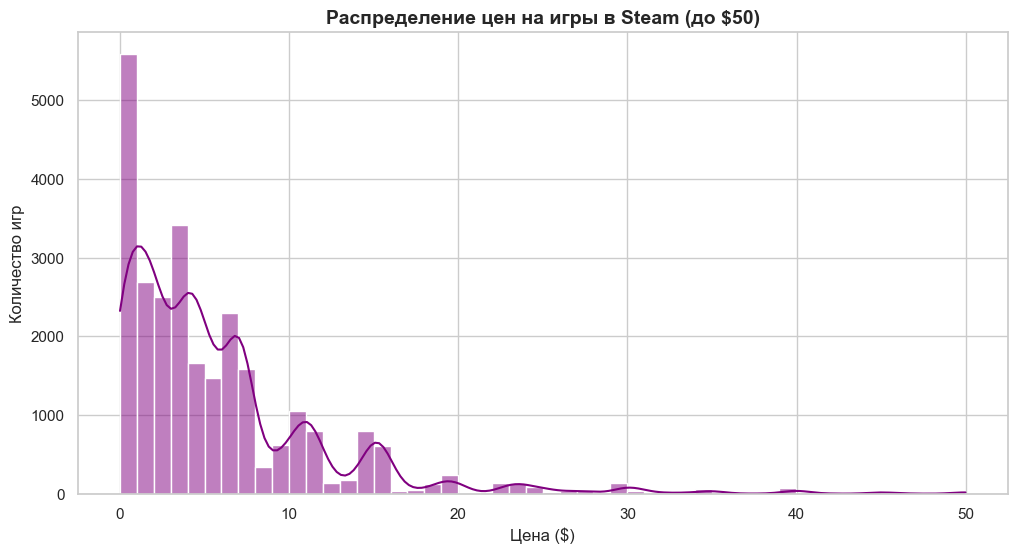

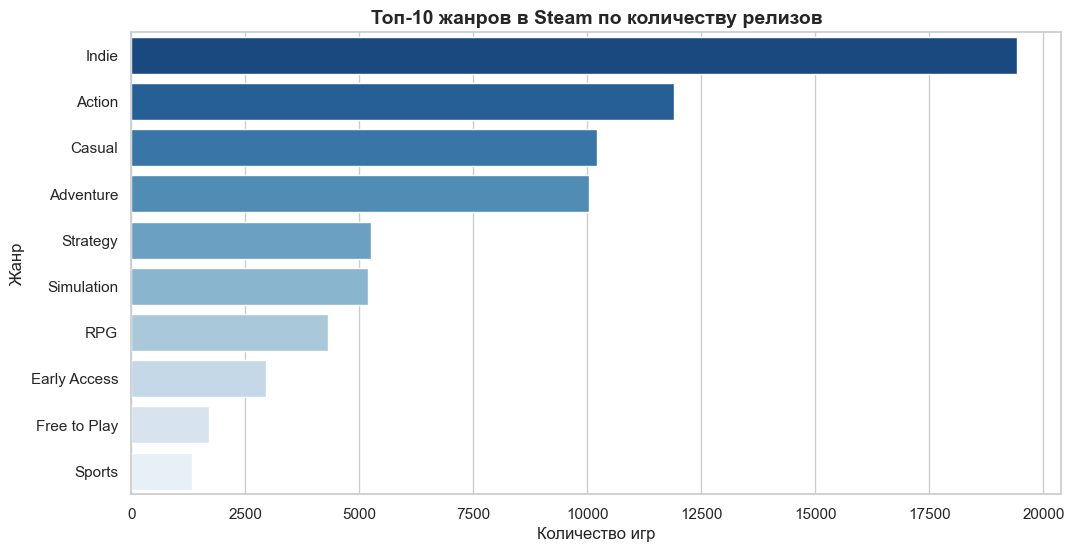

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid") # стиль графиков

# График 1: Распределение цен на игры (ограничим ценой до $50 для наглядности)
plt.figure(figsize=(12, 6))
sns.histplot(df[df['price'] < 50]['price'], bins=50, kde=True, color='purple')
plt.title('Распределение цен на игры в Steam (до $50)', fontsize=14, fontweight='bold')
plt.xlabel('Цена ($)', fontsize=12)
plt.ylabel('Количество игр', fontsize=12)
plt.show()

# График 2: Топ-10 самых популярных жанров по количеству игр
plt.figure(figsize=(12, 6))
top_genres = df['genres'].str.split(';').explode().value_counts().head(10)
sns.barplot(x=top_genres.values, y=top_genres.index, palette='Blues_r', hue=top_genres.index, legend=False)
plt.title('Топ-10 жанров в Steam по количеству релизов', fontsize=14, fontweight='bold')
plt.xlabel('Количество игр', fontsize=12)
plt.ylabel('Жанр', fontsize=12)
plt.show()

Нулевая гипотеза ($H_0$): Средний рейтинг (доля положительных отзывов) у бесплатных игр (price == 0) и платных (price > 0) не имеет статистически значимых различий.

Альтернативная гипотеза ($H_1$): Доля положительных отзывов у бесплатных и платных игр различается.

In [6]:
# тест Манна-Уитни (так как рейтинги распределены ненормально)

from scipy import stats

# 1. Разделяем датасет на две группы: бесплатные и платные игры
free_games = df[df['price'] == 0]['positive_ratio'].dropna()
paid_games = df[df['price'] > 0]['positive_ratio'].dropna()

# 2. Проводим тест Манна-Уитни
stat, p_value = stats.mannwhitneyu(free_games, paid_games, alternative='two-sided')

print(f"Статистика теста: {stat}")
print(f"p-value: {p_value}")

# 3. Делаем вывод по уровню значимости alpha = 0.05
alpha = 0.05
if p_value < alpha:
    print("Отвергаем нулевую гипотезу (H0): различия в рейтингах между бесплатными и платными играми статистически значимы!")
else:
    print("Нет оснований отвергать нулевую гипотезу (H0): статистически значимых различий нет.")

print(f"\nСредняя доля позитивных отзывов у бесплатных игр: {free_games.mean():.3f}")
print(f"Средняя доля позитивных отзывов у платных игр: {paid_games.mean():.3f}")

Статистика теста: 29800450.0
p-value: 2.6902853369654578e-05
Отвергаем нулевую гипотезу (H0): различия в рейтингах между бесплатными и платными играми статистически значимы!

Средняя доля позитивных отзывов у бесплатных игр: 0.719
Средняя доля позитивных отзывов у платных игр: 0.714


In [7]:
# bootstrap

import numpy as np

# Очищаем данные от возможных пропусков
free_games = free_games.dropna()
paid_games = paid_games.dropna()

# Количество итераций бутстрапа
n_iterations = 10000
bootstrap_diffs = []

# Фиксируем seed для воспроизводимости результатов (чтобы цифры не «плавали» при каждом запуске)
np.random.seed(42)

# Цикл бутстрапа
for _ in range(n_iterations):
    # Случайный выбор с возвращением (replace=True) для каждой группы
    free_sample = np.random.choice(free_games, size=len(free_games), replace=True)
    paid_sample = np.random.choice(paid_games, size=len(paid_games), replace=True)
    
    # Считаем разницу средних (среднее бесплатных минус среднее платных)
    diff = np.mean(free_sample) - np.mean(paid_sample)
    bootstrap_diffs.append(diff)

# Превращаем список в numpy-массив
bootstrap_diffs = np.array(bootstrap_diffs)

# Вычисляем 95% доверительный интервал (берём 2.5-й и 97.5-й перцентили)
ci_lower = np.percentile(bootstrap_diffs, 2.5)
ci_upper = np.percentile(bootstrap_diffs, 97.5)

# Реальная разница на исходных данных
real_diff = free_games.mean() - paid_games.mean()

print(f"Реальная разница средних (бесплатные - платные): {real_diff:.4f}")
print(f"95% доверительный интервал: [{ci_lower:.4f}, {ci_upper:.4f}]")

# Проверяем, входит ли ноль в доверительный интервал
if ci_lower <= 0 <= ci_upper:
    print("\nНоль ВХОДИТ в доверительный интервал. Разница статистически не значима.")
else:
    print("\nНоль НЕ входит в доверительный интервал. Разница статистически ЗНАЧИМА!")

Реальная разница средних (бесплатные - платные): 0.0051
95% доверительный интервал: [-0.0024, 0.0127]

Ноль ВХОДИТ в доверительный интервал. Разница статистически не значима.


Анализ рейтингов (Гипотеза о платных и бесплатных играх):Тест Манна-Уитни показал формальную статистическую значимость ($p < 0.001$), так как при больших выборках тест чувствителен к малейшим отклонениям в форме распределений.

Однако оценка разницы средних через Бутстрап (10 000 итераций) показала, что 95% доверительный интервал для разницы средних включает ноль [-0.0024, 0.0127], а реальная разница составляет всего ~0.5%.

Бизнес-вывод: Статистический шум подтверждает, что монетизация игры (платная или бесплатная модель) не влияет на лояльность пользователей в разрезе доли положительных отзывов — качество контента оценивается одинаково в обоих сегментах.